# **PRACTICAL ASSIGNMENT NO. 3**
**Name-Shruti Siddheshwar Thorat**

**Roll No-16**

**PRN-202401040053**

**Batch- A1**

## **HOUSE PRICE PREDICTION USING REGRESSION MODELS**

### **Aim**
To implement and compare **Simple Linear Regression, Multiple Linear Regression, and Polynomial Regression** using both library-based and manual approaches for predicting house prices.

### **Objectives**
- To explore and understand the house price dataset.
- To perform data cleaning and preprocessing.
- To implement three different regression models.
- To understand the mathematical working of regression algorithms.
- To evaluate model performance using **MSE, RMSE, MAE, and R² Score**.
- To compare library-based and manual implementations using tables and graphs.

### **Tools and Technologies**
- **Programming Language:** Python
- **Platform:** Google Colab
- **Libraries:** Pandas, NumPy, Matplotlib, and Scikit-learn
- **Dataset:** Housing Price Prediction Dataset

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Load dataset directly from GitHub
url = "https://raw.githubusercontent.com/Komalharini237/Housing-Case-Study-Multiple-Linear-Regression/main/Housing.csv"

df = pd.read_csv(url)

# Display the first five records
print("FIRST FIVE RECORDS")
display(df.head())

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())


FIRST FIVE RECORDS


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


Dataset shape: (545, 13)
Column names: ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']


## **1. Dataset Exploration**

Dataset exploration is the first step in building a machine learning model. It helps us understand the structure, size, features, and quality of the available data.

In this practical, the **Housing Price Prediction Dataset** is used to predict house prices based on different property features.

The dataset contains information such as **price, area, bedrooms, bathrooms, stories, and parking**. Exploring the dataset helps identify missing values, duplicate records, and the types of data available for analysis.

### **Purpose**
- To understand the number of rows and columns.
- To identify numerical and categorical features.
- To examine descriptive statistics.
- To check for missing values and duplicate records.

In [2]:

print("DATASET INFORMATION")
print("--------------------")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn data types:")
print(df.dtypes)

print("\nStatistical summary:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


DATASET INFORMATION
--------------------
Number of rows: 545
Number of columns: 13

Column data types:
price                int64
area                 int64
bedrooms             int64
bathrooms            int64
stories              int64
mainroad            object
guestroom           object
basement            object
hotwaterheating     object
airconditioning     object
parking              int64
prefarea            object
furnishingstatus    object
dtype: object

Statistical summary:


,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000



Missing values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Duplicate rows: 0


## **2. Data Preprocessing**

Data preprocessing prepares raw data for machine learning. Incomplete, duplicate, or unsuitable data can affect the performance of a model.

The following preprocessing operations are performed:

- **Duplicate Removal:** Duplicate records are removed to avoid repeated observations.
- **Missing Value Handling:** Missing numerical values are filled using the median.
- **Data Type Conversion:** Relevant columns are converted into numerical formats.
- **Data Filtering:** Records with invalid or non-positive house prices and areas are excluded.
- **Feature Selection:** Area, bedrooms, bathrooms, stories, and parking are selected as input features.
- **Target Selection:** The house **price** is selected as the target variable.

These steps help prepare a cleaner dataset for regression analysis.

In [3]:

# Remove duplicate records
df = df.drop_duplicates().copy()

# Select numerical input features
features = [
    "area",
    "bedrooms",
    "bathrooms",
    "stories",
    "parking"
]

target = "price"

# Convert selected columns to numeric values
for col in features + [target]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Replace infinite values and handle missing values
df = df.replace([np.inf, -np.inf], np.nan)

df[features] = df[features].fillna(df[features].median())
df[target] = df[target].fillna(df[target].median())

# Keep only valid, positive house prices and areas
df = df[(df["price"] > 0) & (df["area"] > 0)].copy()

X = df[features]
y = df[target]

print("Preprocessing completed.")
print("Records after cleaning:", len(df))
print("Selected input features:", features)
print("Target variable:", target)
print("Remaining missing values:", df[features + [target]].isnull().sum().sum())


Preprocessing completed.
Records after cleaning: 545
Selected input features: ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
Target variable: price
Remaining missing values: 0


## **3. Exploratory Data Analysis (EDA)**

Exploratory Data Analysis helps us understand patterns and relationships within the dataset using statistical summaries and visualizations.

### **Graphs and Their Purpose**

1. **Price Distribution:** Shows how house prices are distributed across the dataset.
2. **Area vs. Price Scatter Plot:** Helps visualize the relationship between house area and price.
3. **Average Price by Number of Bedrooms:** Compares the average house price for different bedroom counts.
4. **Correlation Heatmap:** Displays the correlation between numerical features and helps identify relationships among variables.

### **Observation**
These visualizations help us understand the data before training the models. The scatter plot and correlation heatmap are particularly useful for examining how house area and other numerical features relate to house prices.

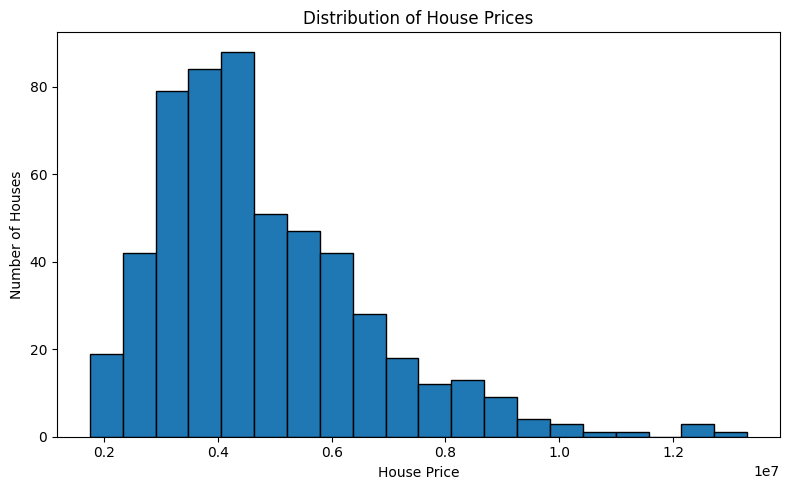

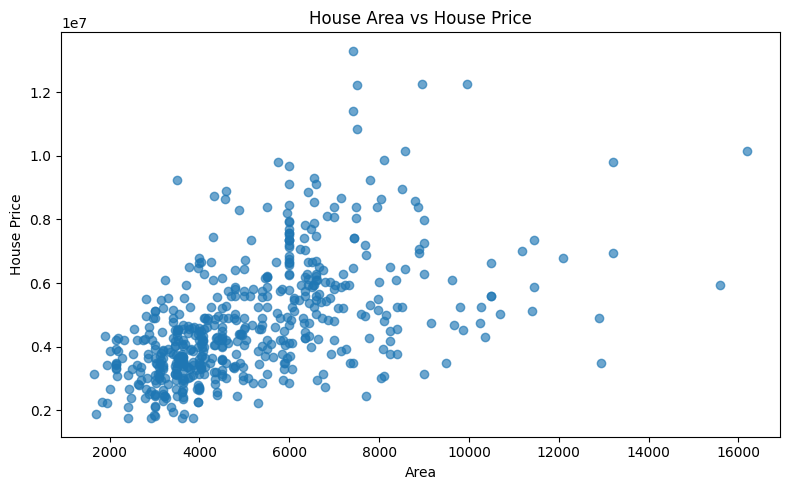

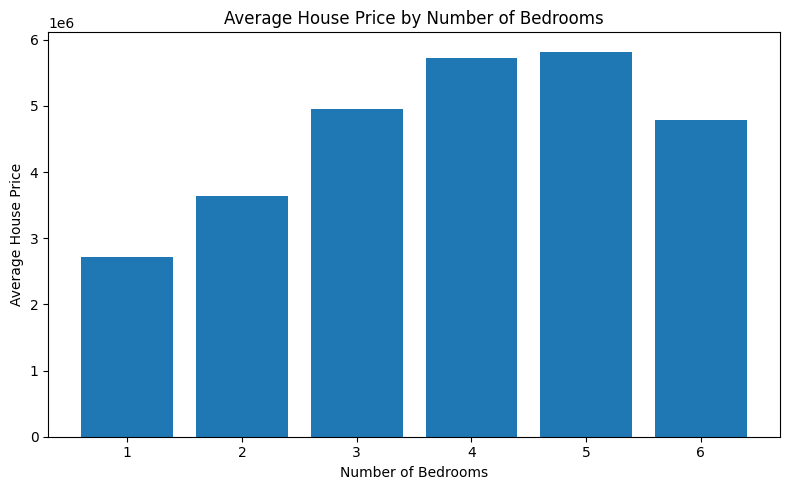

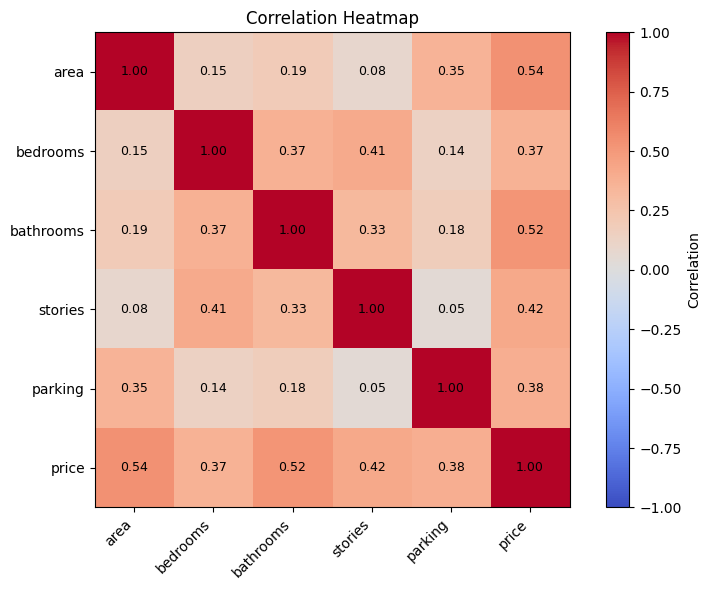

In [4]:

# Graph 1: Distribution of house prices
plt.figure(figsize=(8, 5))
plt.hist(df["price"], bins=20, edgecolor="black")
plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Number of Houses")
plt.tight_layout()
plt.show()

# Graph 2: Area versus price
plt.figure(figsize=(8, 5))
plt.scatter(df["area"], df["price"], alpha=0.65)
plt.title("House Area vs House Price")
plt.xlabel("Area")
plt.ylabel("House Price")
plt.tight_layout()
plt.show()

# Graph 3: Number of bedrooms versus price
bedroom_prices = df.groupby("bedrooms")["price"].mean()

plt.figure(figsize=(8, 5))
plt.bar(bedroom_prices.index.astype(str), bedroom_prices.values)
plt.title("Average House Price by Number of Bedrooms")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Average House Price")
plt.tight_layout()
plt.show()

# Graph 4: Correlation heatmap for numerical variables
corr = df[features + [target]].corr()

plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.columns)), corr.columns)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}",
                 ha="center", va="center", fontsize=9)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


## **4. Splitting the Dataset**

The dataset is divided into two parts: **training data** and **testing data**.

- **Training Set (80%):** Used to train the regression models.
- **Testing Set (20%):** Used to evaluate the models on data that was not used during training.
- **Random State:** A fixed random state is used to make the split reproducible.

For **Simple Linear Regression**, the house area is used as the single input feature. For **Multiple Linear Regression**, multiple numerical features are used to predict house prices.

This separation helps evaluate how well the trained models perform on unseen data.

In [5]:

# Split the complete numerical feature set
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Split the single-feature dataset for simple regression
X_simple_train = X_train[["area"]]
X_simple_test = X_test[["area"]]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 436
Testing records: 109


## **5. Simple Linear Regression Using a Library**

**Simple Linear Regression** is a supervised machine learning algorithm that models the relationship between one independent variable and one dependent variable.

In this practical, **area** is the independent variable (\(X\)), and **house price** is the dependent variable (\(Y\)).

The model is represented by the equation:

\[
Y = mX + c
\]

Where:

- **Y:** Predicted house price
- **X:** House area
- **m:** Slope of the regression line
- **c:** Intercept

The **Scikit-learn LinearRegression** class is used to train the model. The trained model predicts prices for the test data, and its performance is evaluated using MSE, RMSE, MAE, and R² Score.

The actual-versus-predicted graph helps visualize the difference between actual house prices and model predictions.

SIMPLE LINEAR REGRESSION WITH LIBRARY
------------------------------------
Intercept: 2512254.2639593435
Slope: 425.72984193878284
MSE: 3675286604768.185
RMSE: 1917103.7021424233
MAE: 1474748.1337969352
R2 Score: 0.27287851871974644


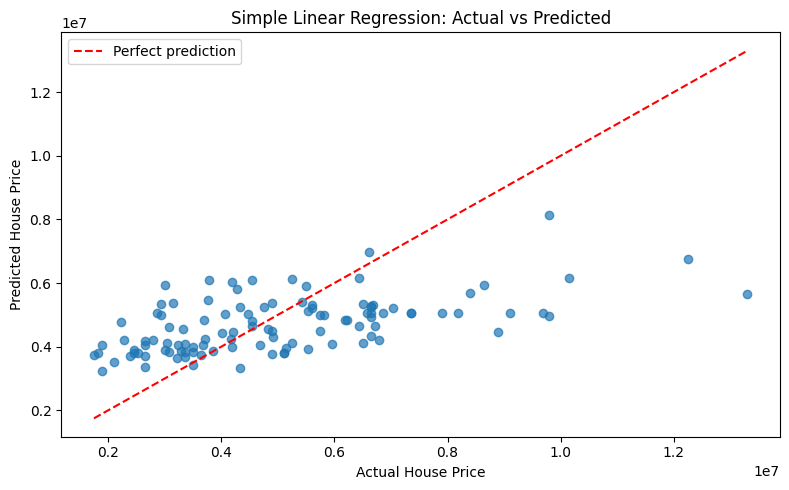

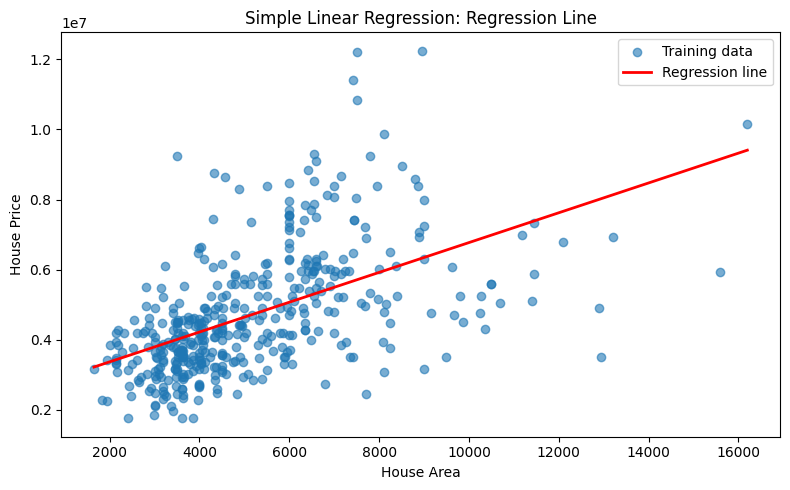

In [6]:

# Train the model
simple_model = LinearRegression()
simple_model.fit(X_simple_train, y_train)

# Predict test values
simple_pred_lib = simple_model.predict(X_simple_test)

# Calculate evaluation metrics
simple_mse_lib = mean_squared_error(y_test, simple_pred_lib)
simple_rmse_lib = np.sqrt(simple_mse_lib)
simple_mae_lib = mean_absolute_error(y_test, simple_pred_lib)
simple_r2_lib = r2_score(y_test, simple_pred_lib)

print("SIMPLE LINEAR REGRESSION WITH LIBRARY")
print("------------------------------------")
print("Intercept:", simple_model.intercept_)
print("Slope:", simple_model.coef_[0])
print("MSE:", simple_mse_lib)
print("RMSE:", simple_rmse_lib)
print("MAE:", simple_mae_lib)
print("R2 Score:", simple_r2_lib)

# Graph 1: Actual versus predicted prices
plt.figure(figsize=(8, 5))
plt.scatter(y_test, simple_pred_lib, alpha=0.7)

low = min(y_test.min(), simple_pred_lib.min())
high = max(y_test.max(), simple_pred_lib.max())
plt.plot([low, high], [low, high], "r--", label="Perfect prediction")

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Simple Linear Regression: Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

# Graph 2: Regression line
plt.figure(figsize=(8, 5))
plt.scatter(X_simple_train["area"], y_train,
            alpha=0.6, label="Training data")

area_line = np.linspace(
    X_simple_train["area"].min(),
    X_simple_train["area"].max(),
    200
)

price_line = simple_model.predict(
    pd.DataFrame({"area": area_line})
)

plt.plot(area_line, price_line, "r-", linewidth=2,
         label="Regression line")

plt.xlabel("House Area")
plt.ylabel("House Price")
plt.title("Simple Linear Regression: Regression Line")
plt.legend()
plt.tight_layout()
plt.show()


## **6. Simple Linear Regression Without a Library**

In this section, Simple Linear Regression is implemented manually using mathematical formulas instead of the Scikit-learn regression model.

The slope and intercept are calculated using the **Least Squares Method**.

The slope is calculated as:

\[
m = \frac{\sum (x_i-\bar{x})(y_i-\bar{y})}{\sum (x_i-\bar{x})^2}
\]

The intercept is calculated as:

\[
c = \bar{y}-m\bar{x}
\]

The predicted price is then calculated using:

\[
\hat{y}=mx+c
\]

Here, \(\bar{x}\) and \(\bar{y}\) represent the mean values of the input and target variables.

This implementation helps explain the mathematical foundation of linear regression and allows its performance to be compared with the library-based model.

SIMPLE LINEAR REGRESSION WITHOUT LIBRARY
---------------------------------------
Intercept: 2512254.263959343
Slope: 425.7298419387829
MSE: 3675286604768.1855
RMSE: 1917103.7021424235
MAE: 1474748.1337969352
R2 Score: 0.27287851871974633


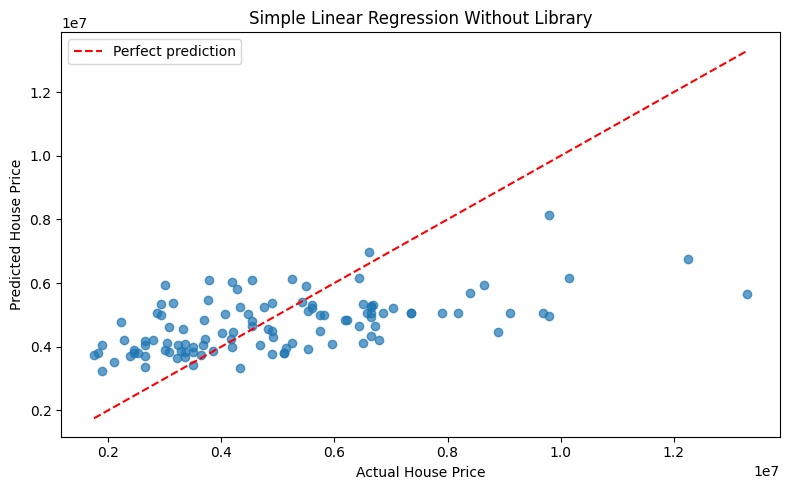

In [7]:

# Convert training data to NumPy arrays
x_train = X_simple_train["area"].to_numpy(dtype=float)
x_test = X_simple_test["area"].to_numpy(dtype=float)

y_train_arr = y_train.to_numpy(dtype=float)
y_test_arr = y_test.to_numpy(dtype=float)

# Calculate slope and intercept manually
x_mean = np.mean(x_train)
y_mean = np.mean(y_train_arr)

slope_manual = np.sum(
    (x_train - x_mean) * (y_train_arr - y_mean)
) / np.sum((x_train - x_mean) ** 2)

intercept_manual = y_mean - slope_manual * x_mean

# Predict test values
simple_pred_manual = intercept_manual + slope_manual * x_test

# Evaluation metrics
simple_mse_manual = mean_squared_error(
    y_test_arr, simple_pred_manual
)
simple_rmse_manual = np.sqrt(simple_mse_manual)
simple_mae_manual = mean_absolute_error(
    y_test_arr, simple_pred_manual
)
simple_r2_manual = r2_score(y_test_arr, simple_pred_manual)

print("SIMPLE LINEAR REGRESSION WITHOUT LIBRARY")
print("---------------------------------------")
print("Intercept:", intercept_manual)
print("Slope:", slope_manual)
print("MSE:", simple_mse_manual)
print("RMSE:", simple_rmse_manual)
print("MAE:", simple_mae_manual)
print("R2 Score:", simple_r2_manual)

# Actual versus predicted graph
plt.figure(figsize=(8, 5))
plt.scatter(y_test_arr, simple_pred_manual, alpha=0.7)

low = min(y_test_arr.min(), simple_pred_manual.min())
high = max(y_test_arr.max(), simple_pred_manual.max())
plt.plot([low, high], [low, high], "r--",
         label="Perfect prediction")

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Simple Linear Regression Without Library")
plt.legend()
plt.tight_layout()
plt.show()


## **7. Comparison of Simple Linear Regression Models**

The library-based and manual implementations of Simple Linear Regression are compared using the same evaluation metrics.

The comparison includes:

- **MSE:** Mean Squared Error
- **RMSE:** Root Mean Squared Error
- **MAE:** Mean Absolute Error
- **R² Score:** Coefficient of Determination

Lower MSE, RMSE, and MAE generally indicate smaller prediction errors. A higher R² Score generally indicates that the model explains a greater proportion of the variation in house prices.

The comparison table and graphs help identify differences between the two implementations.

,Metric,With Library,Without Library
0,MSE,3.675287e+12,3.675287e+12
1,RMSE,1.917104e+06,1.917104e+06
2,MAE,1.474748e+06,1.474748e+06
3,R2 Score,2.729000e-01,2.729000e-01


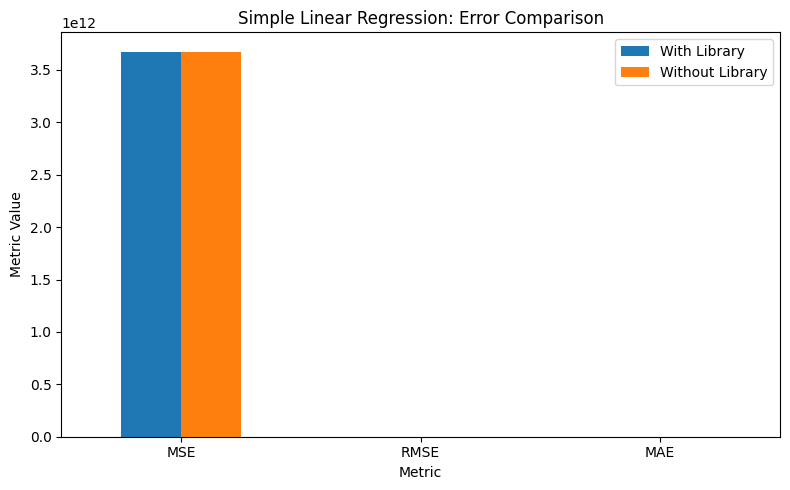

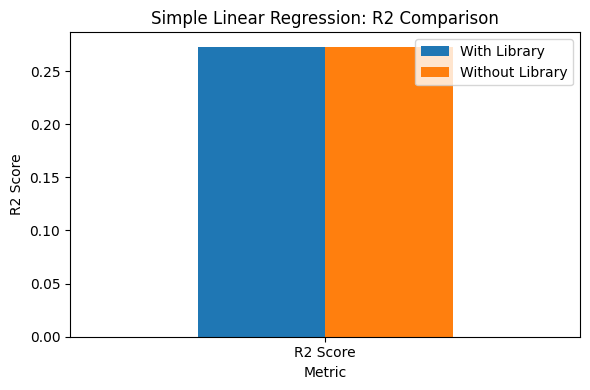

In [8]:

simple_comparison = pd.DataFrame({
    "Metric": ["MSE", "RMSE", "MAE", "R2 Score"],
    "With Library": [
        simple_mse_lib, simple_rmse_lib,
        simple_mae_lib, simple_r2_lib
    ],
    "Without Library": [
        simple_mse_manual, simple_rmse_manual,
        simple_mae_manual, simple_r2_manual
    ]
})

display(simple_comparison.round(4))

# Compare error metrics
simple_comparison.set_index("Metric").loc[
    ["MSE", "RMSE", "MAE"]
].plot(kind="bar", figsize=(8, 5))

plt.title("Simple Linear Regression: Error Comparison")
plt.ylabel("Metric Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Compare R2 separately
simple_comparison.set_index("Metric").loc[
    ["R2 Score"]
].plot(kind="bar", figsize=(6, 4))

plt.title("Simple Linear Regression: R2 Comparison")
plt.ylabel("R2 Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## **8. Multiple Linear Regression Using a Library**

**Multiple Linear Regression** predicts a dependent variable using two or more independent variables.

In this practical, house price is predicted using the following features:

- **Area**
- **Bedrooms**
- **Bathrooms**
- **Stories**
- **Parking**

The model can be represented as:

\[
Y=b_0+b_1X_1+b_2X_2+\cdots+b_nX_n
\]

Where **Y** is the predicted house price, **\(b_0\)** is the intercept, and the coefficients represent the contribution of the input features to the prediction.

The Scikit-learn **LinearRegression** class is used to train the model. Predictions are generated for the test dataset, and performance is measured using MSE, RMSE, MAE, and R² Score.

Using multiple features allows the model to consider several property characteristics rather than relying only on house area.

MULTIPLE LINEAR REGRESSION WITH LIBRARY
--------------------------------------
Intercept: 51999.67680883873

Feature coefficients:
area: 308.8670
bedrooms: 151246.7506
bathrooms: 1185731.7137
stories: 495100.7627
parking: 337660.8303

MSE: 2292721545725.3623
RMSE: 1514173.5520492233
MAE: 1127483.352323519
R2 Score: 0.5464062355495871


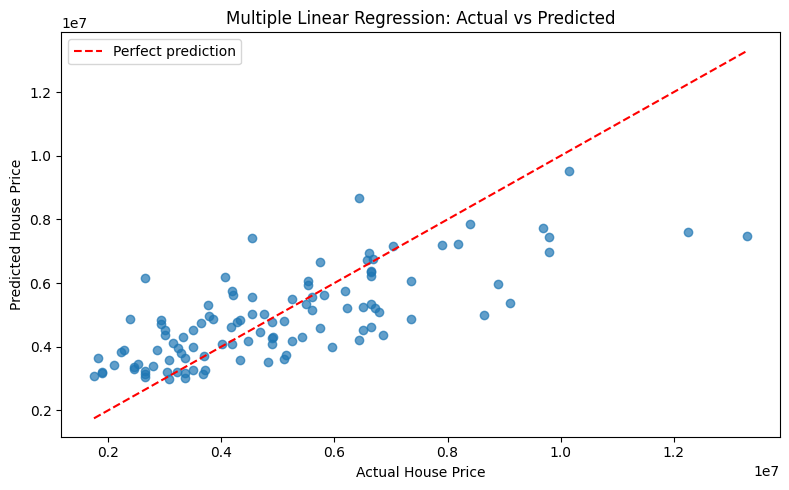

In [9]:

# Train multiple linear regression
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

# Predict test prices
multiple_pred_lib = multiple_model.predict(X_test)

# Evaluate
multiple_mse_lib = mean_squared_error(y_test, multiple_pred_lib)
multiple_rmse_lib = np.sqrt(multiple_mse_lib)
multiple_mae_lib = mean_absolute_error(y_test, multiple_pred_lib)
multiple_r2_lib = r2_score(y_test, multiple_pred_lib)

print("MULTIPLE LINEAR REGRESSION WITH LIBRARY")
print("--------------------------------------")
print("Intercept:", multiple_model.intercept_)

print("\nFeature coefficients:")
for name, coef in zip(features, multiple_model.coef_):
    print(f"{name}: {coef:.4f}")

print("\nMSE:", multiple_mse_lib)
print("RMSE:", multiple_rmse_lib)
print("MAE:", multiple_mae_lib)
print("R2 Score:", multiple_r2_lib)

# Actual versus predicted graph
plt.figure(figsize=(8, 5))
plt.scatter(y_test, multiple_pred_lib, alpha=0.7)

low = min(y_test.min(), multiple_pred_lib.min())
high = max(y_test.max(), multiple_pred_lib.max())
plt.plot([low, high], [low, high], "r--",
         label="Perfect prediction")

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()


## **9. Multiple Linear Regression Without a Library**

In this section, Multiple Linear Regression is implemented manually using **Gradient Descent** instead of using Scikit-learn's regression model.

Gradient Descent is an optimization algorithm that repeatedly updates model parameters to reduce the prediction error.

### **Working Steps**
1. Prepare the input features and target values.
2. Standardize the features and target to help the optimization process.
3. Initialize the model parameters.
4. Calculate predicted values and the prediction error.
5. Update the parameters using the gradients of the error function.
6. Repeat the updates for a specified number of iterations.
7. Convert predictions back to the original house-price scale.
8. Evaluate the model using MSE, RMSE, MAE, and R² Score.

This approach helps demonstrate how a regression model can learn its parameters through iterative optimization.

MULTIPLE LINEAR REGRESSION WITHOUT LIBRARY
-----------------------------------------
Intercept in standardized model: -2.1550040039914474e-16
MSE: 2292721545725.3667
RMSE: 1514173.552049225
MAE: 1127483.3523235198
R2 Score: 0.5464062355495862


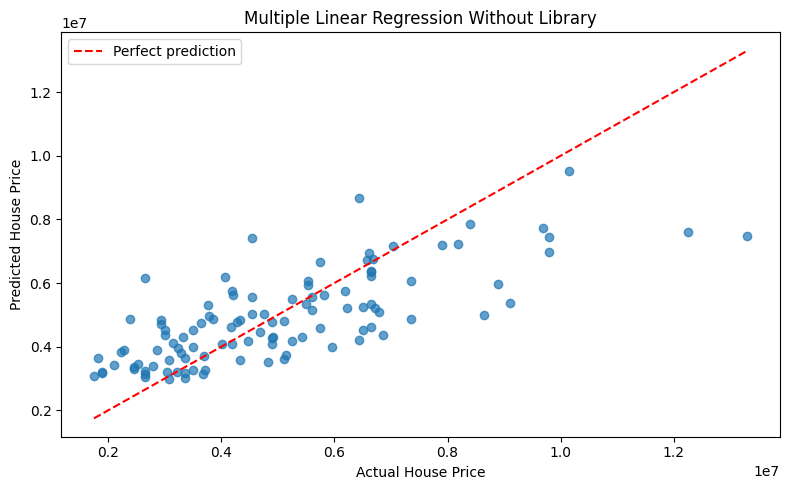

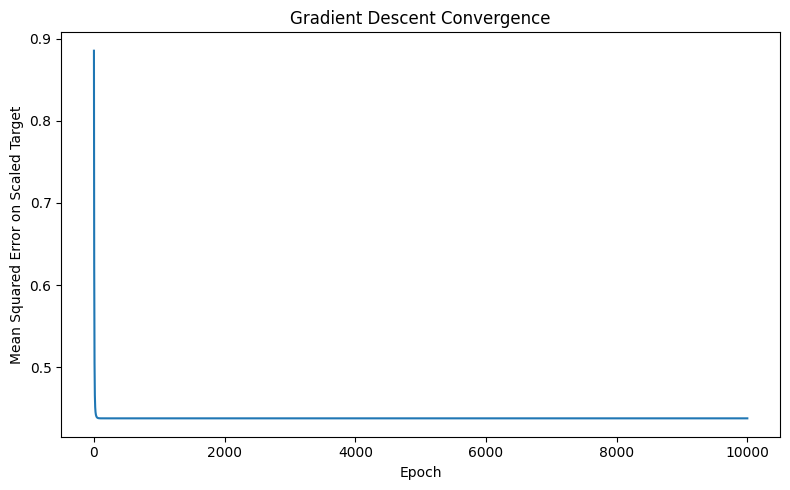

In [10]:

# Convert features and targets to NumPy arrays
X_train_arr = X_train.to_numpy(dtype=float)
X_test_arr = X_test.to_numpy(dtype=float)

y_train_arr = y_train.to_numpy(dtype=float)
y_test_arr = y_test.to_numpy(dtype=float)

# Standardize using training data only
X_mean = X_train_arr.mean(axis=0)
X_std = X_train_arr.std(axis=0)
X_std[X_std == 0] = 1

X_train_scaled = (X_train_arr - X_mean) / X_std
X_test_scaled = (X_test_arr - X_mean) / X_std

y_mean = y_train_arr.mean()
y_std = y_train_arr.std()

y_train_scaled = (y_train_arr - y_mean) / y_std

# Add a column of ones for the intercept
X_train_b = np.column_stack([
    np.ones(len(X_train_scaled)), X_train_scaled
])
X_test_b = np.column_stack([
    np.ones(len(X_test_scaled)), X_test_scaled
])

# Initialize coefficients
weights = np.zeros(X_train_b.shape[1])

learning_rate = 0.03
epochs = 10000
n = len(y_train_scaled)

cost_history = []

# Gradient descent
for epoch in range(epochs):
    predictions = X_train_b @ weights
    errors = predictions - y_train_scaled

    gradients = (2 / n) * (X_train_b.T @ errors)
    weights -= learning_rate * gradients

    cost = np.mean((X_train_b @ weights - y_train_scaled) ** 2)
    cost_history.append(cost)

# Predict and convert to original price units
multiple_pred_manual = (
    X_test_b @ weights
) * y_std + y_mean

# Evaluation
multiple_mse_manual = mean_squared_error(
    y_test_arr, multiple_pred_manual
)
multiple_rmse_manual = np.sqrt(multiple_mse_manual)
multiple_mae_manual = mean_absolute_error(
    y_test_arr, multiple_pred_manual
)
multiple_r2_manual = r2_score(
    y_test_arr, multiple_pred_manual
)

print("MULTIPLE LINEAR REGRESSION WITHOUT LIBRARY")
print("-----------------------------------------")
print("Intercept in standardized model:", weights[0])
print("MSE:", multiple_mse_manual)
print("RMSE:", multiple_rmse_manual)
print("MAE:", multiple_mae_manual)
print("R2 Score:", multiple_r2_manual)

# Actual versus predicted graph
plt.figure(figsize=(8, 5))
plt.scatter(y_test_arr, multiple_pred_manual, alpha=0.7)

low = min(y_test_arr.min(), multiple_pred_manual.min())
high = max(y_test_arr.max(), multiple_pred_manual.max())
plt.plot([low, high], [low, high], "r--",
         label="Perfect prediction")

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Multiple Linear Regression Without Library")
plt.legend()
plt.tight_layout()
plt.show()

# Gradient descent convergence graph
plt.figure(figsize=(8, 5))
plt.plot(cost_history)
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error on Scaled Target")
plt.title("Gradient Descent Convergence")
plt.tight_layout()
plt.show()


## **10. Comparison of Multiple Linear Regression Models**

The library-based implementation and the manual Gradient Descent implementation are evaluated using the same test dataset.

Their performance is compared using **MSE, RMSE, MAE, and R² Score**.

The results show how the two methods perform when several house features are used together to predict prices.

The comparison also demonstrates the difference between using a ready-made machine learning library and implementing the learning process manually.

,Metric,With Library,Without Library
0,MSE,2.292722e+12,2.292722e+12
1,RMSE,1.514174e+06,1.514174e+06
2,MAE,1.127483e+06,1.127483e+06
3,R2 Score,5.464000e-01,5.464000e-01


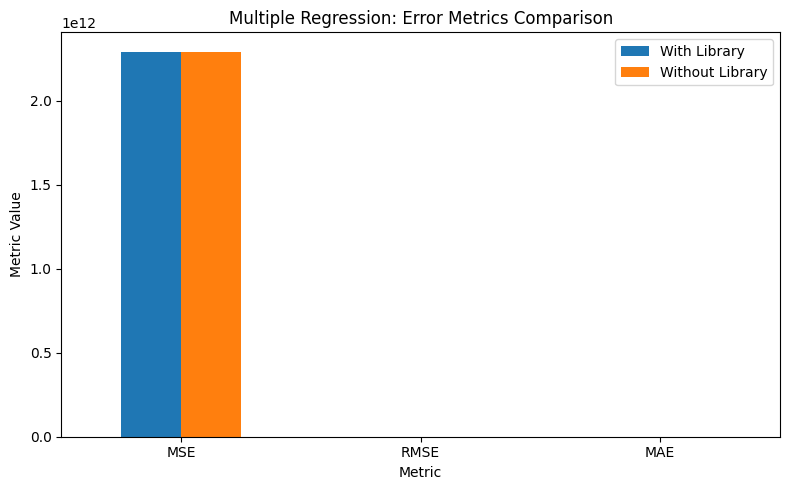

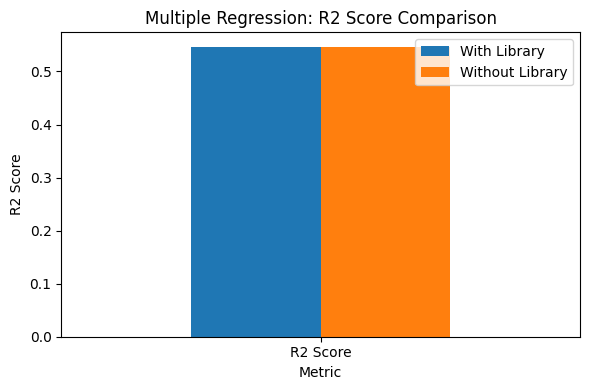

In [11]:

multiple_comparison = pd.DataFrame({
    "Metric": ["MSE", "RMSE", "MAE", "R2 Score"],
    "With Library": [
        multiple_mse_lib, multiple_rmse_lib,
        multiple_mae_lib, multiple_r2_lib
    ],
    "Without Library": [
        multiple_mse_manual, multiple_rmse_manual,
        multiple_mae_manual, multiple_r2_manual
    ]
})

display(multiple_comparison.round(4))

# Error metrics comparison
multiple_comparison.set_index("Metric").loc[
    ["MSE", "RMSE", "MAE"]
].plot(kind="bar", figsize=(8, 5))

plt.title("Multiple Regression: Error Metrics Comparison")
plt.ylabel("Metric Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# R2 comparison
multiple_comparison.set_index("Metric").loc[
    ["R2 Score"]
].plot(kind="bar", figsize=(6, 4))

plt.title("Multiple Regression: R2 Score Comparison")
plt.ylabel("R2 Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## **11. Polynomial Regression Using a Library**

**Polynomial Regression** is used to model a non-linear relationship between an input variable and a target variable by adding polynomial terms.

In this practical, house area is used as the input feature, and house price is the target variable.

For a second-degree polynomial, the model can be represented as:

\[
Y=b_0+b_1X+b_2X^2
\]

Here, **\(X^2\)** represents the squared input feature, which allows the model to represent a curved relationship.

The input feature is standardized, and **PolynomialFeatures** from Scikit-learn generates the polynomial features. A Linear Regression model is then trained on these transformed features.

The model's predictions are evaluated using MSE, RMSE, MAE, and R² Score. A polynomial curve is plotted to visualize the fitted relationship between area and price.

POLYNOMIAL REGRESSION WITH LIBRARY
---------------------------------
Intercept: 4917278.677077216
Coefficients: [1234930.09619647 -211235.77748429]
MSE: 3562004338817.5815
RMSE: 1887327.300395345
MAE: 1435042.8099165638
R2 Score: 0.29529036788381513


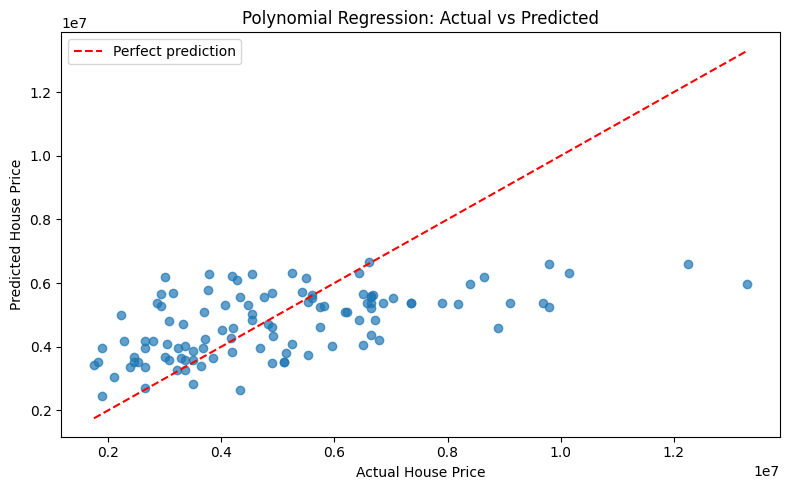

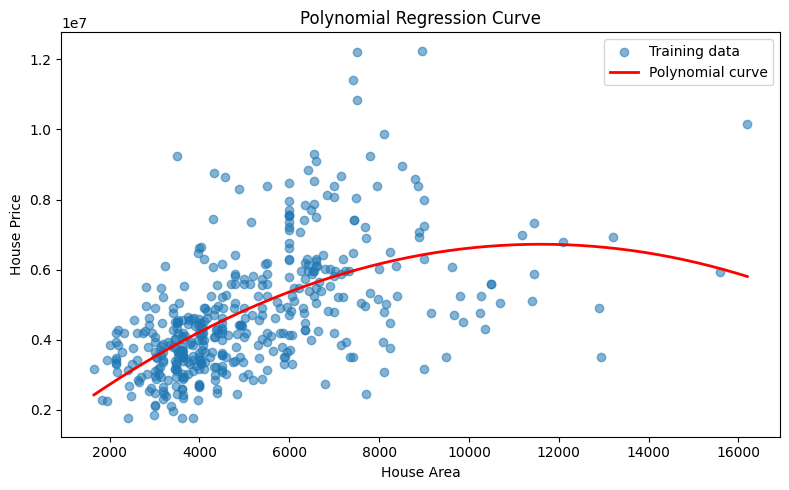

In [12]:

# Use house area as the single input feature
poly_mean = X_simple_train["area"].mean()
poly_std = X_simple_train["area"].std()

if poly_std == 0:
    poly_std = 1

z_train = (
    X_simple_train["area"].to_numpy(dtype=float) - poly_mean
) / poly_std

z_test = (
    X_simple_test["area"].to_numpy(dtype=float) - poly_mean
) / poly_std

# Create degree-2 polynomial features
poly_transformer = PolynomialFeatures(degree=2, include_bias=False)

Z_train_poly = poly_transformer.fit_transform(z_train.reshape(-1, 1))
Z_test_poly = poly_transformer.transform(z_test.reshape(-1, 1))

# Train polynomial regression
poly_model = LinearRegression()
poly_model.fit(Z_train_poly, y_train)

# Predict test prices
poly_pred_lib = poly_model.predict(Z_test_poly)

# Evaluation
poly_mse_lib = mean_squared_error(y_test, poly_pred_lib)
poly_rmse_lib = np.sqrt(poly_mse_lib)
poly_mae_lib = mean_absolute_error(y_test, poly_pred_lib)
poly_r2_lib = r2_score(y_test, poly_pred_lib)

print("POLYNOMIAL REGRESSION WITH LIBRARY")
print("---------------------------------")
print("Intercept:", poly_model.intercept_)
print("Coefficients:", poly_model.coef_)
print("MSE:", poly_mse_lib)
print("RMSE:", poly_rmse_lib)
print("MAE:", poly_mae_lib)
print("R2 Score:", poly_r2_lib)

# Actual versus predicted graph
plt.figure(figsize=(8, 5))
plt.scatter(y_test, poly_pred_lib, alpha=0.7)

low = min(y_test.min(), poly_pred_lib.min())
high = max(y_test.max(), poly_pred_lib.max())
plt.plot([low, high], [low, high], "r--",
         label="Perfect prediction")

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Polynomial Regression: Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

# Polynomial curve
z_line = np.linspace(z_train.min(), z_train.max(), 200)
z_line_poly = poly_transformer.transform(z_line.reshape(-1, 1))
price_line = poly_model.predict(z_line_poly)
area_line = z_line * poly_std + poly_mean

plt.figure(figsize=(8, 5))
plt.scatter(X_simple_train["area"], y_train,
            alpha=0.55, label="Training data")
plt.plot(area_line, price_line, "r-", linewidth=2,
         label="Polynomial curve")

plt.xlabel("House Area")
plt.ylabel("House Price")
plt.title("Polynomial Regression Curve")
plt.legend()
plt.tight_layout()
plt.show()


## **12. Polynomial Regression Without a Library**

In this section, Polynomial Regression is implemented manually without using Scikit-learn's polynomial feature transformation or regression model.

For a second-degree polynomial, the design matrix contains three terms:

- **Constant term:** \(1\)
- **Linear term:** \(X\)
- **Squared term:** \(X^2\)

The model is represented as:

\[
Y=b_0+b_1X+b_2X^2
\]

The coefficients are estimated using **NumPy's least-squares function, `np.linalg.lstsq()`**. This function finds coefficients that minimize the sum of squared differences between actual and predicted values.

The manual implementation is then evaluated using MSE, RMSE, MAE, and R² Score, and its predictions are visualized using graphs.

POLYNOMIAL REGRESSION WITHOUT LIBRARY
------------------------------------
Intercept: 4917278.677077233
Linear coefficient: 1234930.0961964617
Quadratic coefficient: -211235.77748428972
MSE: 3562004338817.5767
RMSE: 1887327.300395344
MAE: 1435042.809916566
R2 Score: 0.29529036788381613


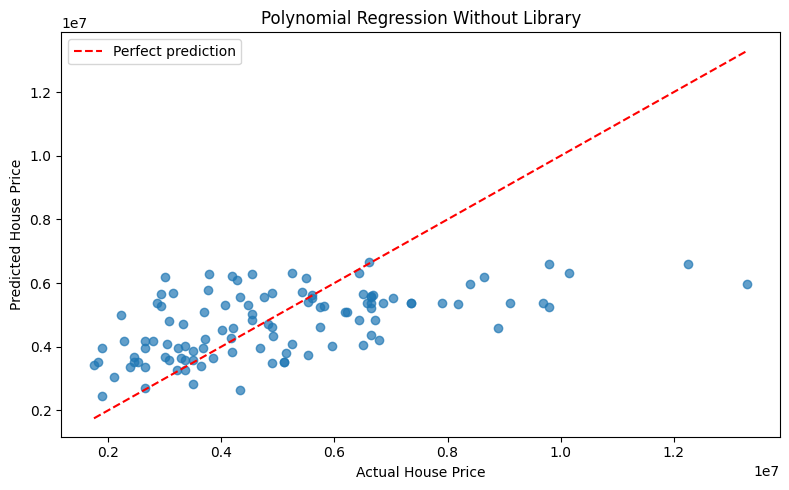

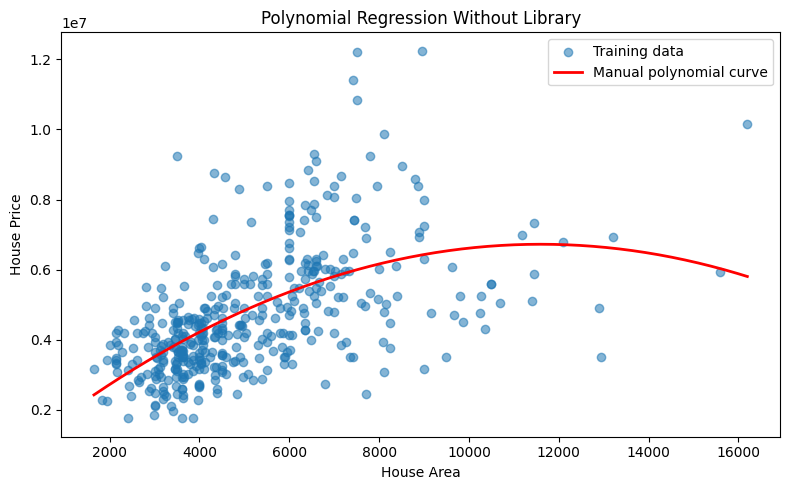

In [13]:

# Manually construct polynomial features
Z_train_manual = np.column_stack([
    np.ones(len(z_train)),
    z_train,
    z_train ** 2
])

Z_test_manual = np.column_stack([
    np.ones(len(z_test)),
    z_test,
    z_test ** 2
])

# Calculate coefficients using least squares
poly_coefficients, residuals, rank, singular_values = np.linalg.lstsq(
    Z_train_manual,
    y_train.to_numpy(dtype=float),
    rcond=None
)

# Predict test prices
poly_pred_manual = Z_test_manual @ poly_coefficients

# Evaluation
poly_mse_manual = mean_squared_error(
    y_test.to_numpy(dtype=float), poly_pred_manual
)
poly_rmse_manual = np.sqrt(poly_mse_manual)
poly_mae_manual = mean_absolute_error(
    y_test.to_numpy(dtype=float), poly_pred_manual
)
poly_r2_manual = r2_score(
    y_test.to_numpy(dtype=float), poly_pred_manual
)

print("POLYNOMIAL REGRESSION WITHOUT LIBRARY")
print("------------------------------------")
print("Intercept:", poly_coefficients[0])
print("Linear coefficient:", poly_coefficients[1])
print("Quadratic coefficient:", poly_coefficients[2])
print("MSE:", poly_mse_manual)
print("RMSE:", poly_rmse_manual)
print("MAE:", poly_mae_manual)
print("R2 Score:", poly_r2_manual)

# Actual versus predicted graph
plt.figure(figsize=(8, 5))
plt.scatter(y_test, poly_pred_manual, alpha=0.7)

low = min(y_test.min(), poly_pred_manual.min())
high = max(y_test.max(), poly_pred_manual.max())
plt.plot([low, high], [low, high], "r--",
         label="Perfect prediction")

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Polynomial Regression Without Library")
plt.legend()
plt.tight_layout()
plt.show()

# Manual polynomial curve
price_line_manual = (
    poly_coefficients[0]
    + poly_coefficients[1] * z_line
    + poly_coefficients[2] * z_line ** 2
)

plt.figure(figsize=(8, 5))
plt.scatter(X_simple_train["area"], y_train,
            alpha=0.55, label="Training data")
plt.plot(area_line, price_line_manual, "r-",
         linewidth=2, label="Manual polynomial curve")

plt.xlabel("House Area")
plt.ylabel("House Price")
plt.title("Polynomial Regression Without Library")
plt.legend()
plt.tight_layout()
plt.show()


## **13. Comparison of Polynomial Regression Models**

The library-based and manual Polynomial Regression implementations are compared using the same evaluation metrics.

The comparison includes **MSE, RMSE, MAE, and R² Score** to measure prediction error and goodness of fit.

The results help determine whether both implementations produce similar predictions and how well a second-degree polynomial models the relationship between house area and house price.

,Metric,With Library,Without Library
0,MSE,3.562004e+12,3.562004e+12
1,RMSE,1.887327e+06,1.887327e+06
2,MAE,1.435043e+06,1.435043e+06
3,R2 Score,2.953000e-01,2.953000e-01


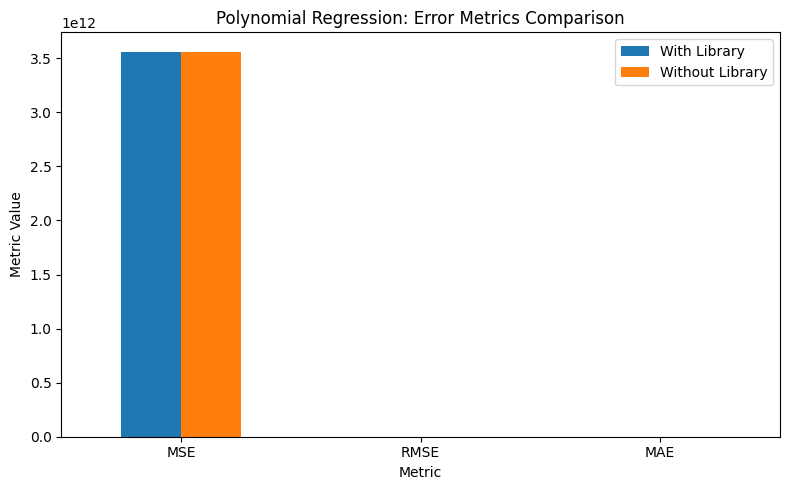

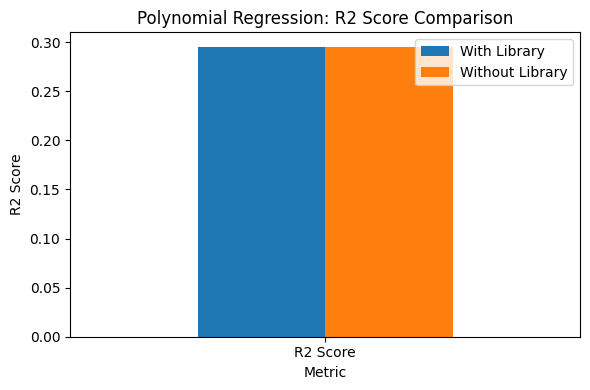

In [14]:

polynomial_comparison = pd.DataFrame({
    "Metric": ["MSE", "RMSE", "MAE", "R2 Score"],
    "With Library": [
        poly_mse_lib, poly_rmse_lib, poly_mae_lib, poly_r2_lib
    ],
    "Without Library": [
        poly_mse_manual, poly_rmse_manual,
        poly_mae_manual, poly_r2_manual
    ]
})

display(polynomial_comparison.round(4))

# Compare error metrics
polynomial_comparison.set_index("Metric").loc[
    ["MSE", "RMSE", "MAE"]
].plot(kind="bar", figsize=(8, 5))

plt.title("Polynomial Regression: Error Metrics Comparison")
plt.ylabel("Metric Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Compare R2 score separately
polynomial_comparison.set_index("Metric").loc[
    ["R2 Score"]
].plot(kind="bar", figsize=(6, 4))

plt.title("Polynomial Regression: R2 Score Comparison")
plt.ylabel("R2 Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## **14. Overall Comparison of Regression Models**

In this section, all three regression techniques are compared:

1. **Simple Linear Regression**
2. **Multiple Linear Regression**
3. **Polynomial Regression**

Each technique has a library-based implementation and a manual implementation, giving a total of six model implementations.

The results are compared using **MSE, RMSE, MAE, and R² Score**. This comparison provides an overall view of the prediction performance of each approach.

A model with lower error values and a higher R² Score may be considered better based on these metrics. However, the final selection should be based on the actual test results rather than assumptions about which regression technique will perform best.

In [15]:

# Combine all model results
final_results = pd.DataFrame([
    {
        "Model": "Simple Linear Regression",
        "Implementation": "With Library",
        "MSE": simple_mse_lib,
        "RMSE": simple_rmse_lib,
        "MAE": simple_mae_lib,
        "R2 Score": simple_r2_lib
    },
    {
        "Model": "Simple Linear Regression",
        "Implementation": "Without Library",
        "MSE": simple_mse_manual,
        "RMSE": simple_rmse_manual,
        "MAE": simple_mae_manual,
        "R2 Score": simple_r2_manual
    },
    {
        "Model": "Multiple Linear Regression",
        "Implementation": "With Library",
        "MSE": multiple_mse_lib,
        "RMSE": multiple_rmse_lib,
        "MAE": multiple_mae_lib,
        "R2 Score": multiple_r2_lib
    },
    {
        "Model": "Multiple Linear Regression",
        "Implementation": "Without Library",
        "MSE": multiple_mse_manual,
        "RMSE": multiple_rmse_manual,
        "MAE": multiple_mae_manual,
        "R2 Score": multiple_r2_manual
    },
    {
        "Model": "Polynomial Regression",
        "Implementation": "With Library",
        "MSE": poly_mse_lib,
        "RMSE": poly_rmse_lib,
        "MAE": poly_mae_lib,
        "R2 Score": poly_r2_lib
    },
    {
        "Model": "Polynomial Regression",
        "Implementation": "Without Library",
        "MSE": poly_mse_manual,
        "RMSE": poly_rmse_manual,
        "MAE": poly_mae_manual,
        "R2 Score": poly_r2_manual
    }
])

display(final_results.round(4))


,Model,Implementation,MSE,RMSE,MAE,R2 Score
0,Simple Linear Regression,With Library,3.675287e+12,1.917104e+06,1.474748e+06,0.2729
1,Simple Linear Regression,Without Library,3.675287e+12,1.917104e+06,1.474748e+06,0.2729
2,Multiple Linear Regression,With Library,2.292722e+12,1.514174e+06,1.127483e+06,0.5464
3,Multiple Linear Regression,Without Library,2.292722e+12,1.514174e+06,1.127483e+06,0.5464
4,Polynomial Regression,With Library,3.562004e+12,1.887327e+06,1.435043e+06,0.2953
5,Polynomial Regression,Without Library,3.562004e+12,1.887327e+06,1.435043e+06,0.2953


## **15. Graphical Comparison of Regression Models**

Graphs are used to compare the performance of the library-based Simple Linear Regression, Multiple Linear Regression, and Polynomial Regression models.

The error metrics **MSE, RMSE, and MAE** measure prediction errors, while the **R² Score** indicates how much variation in house prices is explained by a model.

The bar charts make it easier to compare model performance visually. **Lower error values and a higher R² Score generally indicate better performance.**

The final conclusion should be drawn from the calculated metrics and the observed graphs.

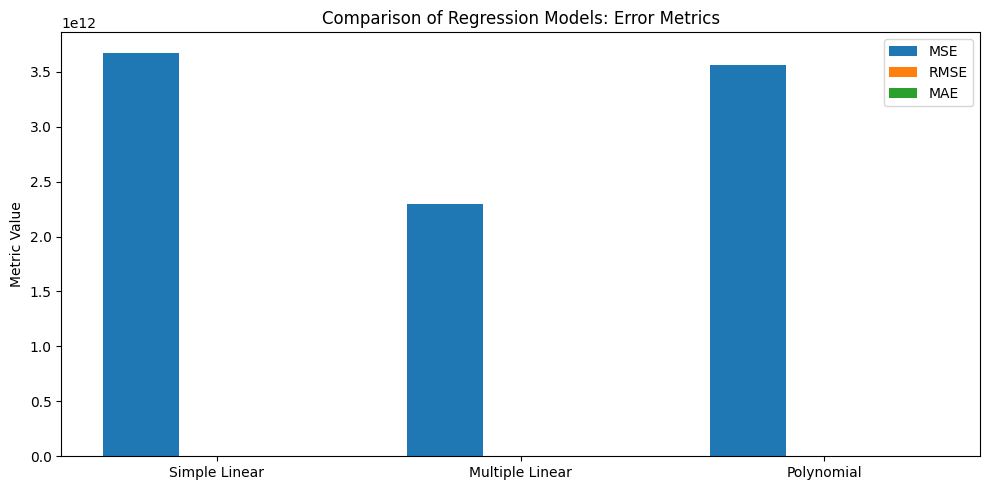

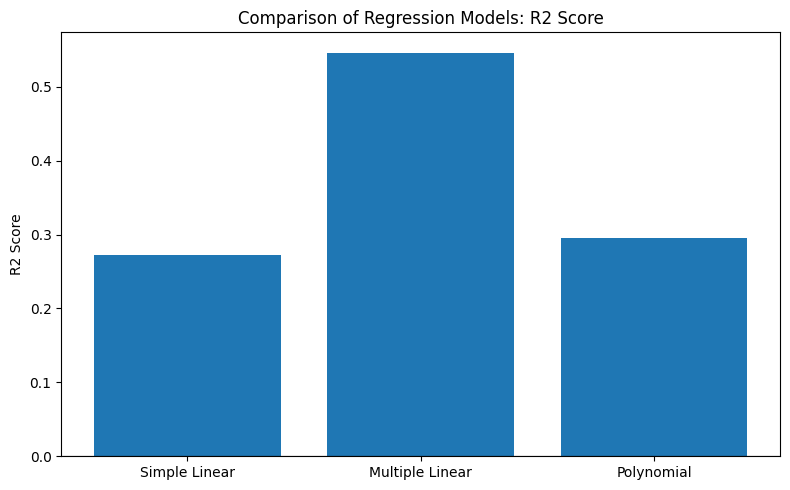

In [16]:

# Use the library-based models for model-to-model comparison
model_names = [
    "Simple Linear",
    "Multiple Linear",
    "Polynomial"
]

model_mse = [simple_mse_lib, multiple_mse_lib, poly_mse_lib]
model_rmse = [simple_rmse_lib, multiple_rmse_lib, poly_rmse_lib]
model_mae = [simple_mae_lib, multiple_mae_lib, poly_mae_lib]
model_r2 = [simple_r2_lib, multiple_r2_lib, poly_r2_lib]

# Compare error metrics
x = np.arange(len(model_names))
width = 0.25

plt.figure(figsize=(10, 5))
plt.bar(x - width, model_mse, width, label="MSE")
plt.bar(x, model_rmse, width, label="RMSE")
plt.bar(x + width, model_mae, width, label="MAE")

plt.xticks(x, model_names)
plt.ylabel("Metric Value")
plt.title("Comparison of Regression Models: Error Metrics")
plt.legend()
plt.tight_layout()
plt.show()

# Compare R2 scores separately
plt.figure(figsize=(8, 5))
plt.bar(model_names, model_r2)
plt.axhline(0, color="black", linewidth=0.8)

plt.ylabel("R2 Score")
plt.title("Comparison of Regression Models: R2 Score")
plt.tight_layout()
plt.show()


In [17]:

# Compare library-based models using test-set RMSE
best_index = int(np.argmin(model_rmse))
best_model = model_names[best_index]

print("FINAL MODEL COMPARISON")
print("----------------------")
print("Best model by test RMSE:", best_model)
print("RMSE:", model_rmse[best_index])
print("MAE:", model_mae[best_index])
print("R2 Score:", model_r2[best_index])

print("\nInterpretation:")
print("Lower RMSE and MAE indicate lower prediction errors.")
print("A higher R2 score generally indicates a better fit.")
print("Use the test-set results to compare the models.")


FINAL MODEL COMPARISON
----------------------
Best model by test RMSE: Multiple Linear
RMSE: 1514173.5520492233
MAE: 1127483.352323519
R2 Score: 0.5464062355495871

Interpretation:
Lower RMSE and MAE indicate lower prediction errors.
A higher R2 score generally indicates a better fit.
Use the test-set results to compare the models.


## **16. Conclusion**

In this practical, **Simple Linear Regression, Multiple Linear Regression, and Polynomial Regression** were implemented using both library-based and manual approaches for house price prediction.

The dataset was explored and preprocessed before training and testing the models. Their performance was evaluated using **Mean Squared Error (MSE), Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and R² Score**.

The experiment demonstrated the use of a single feature, multiple features, and polynomial features for predicting house prices. It also helped develop an understanding of the mathematical working of regression algorithms, including the Least Squares Method and Gradient Descent.

The comparison tables and graphs provide a clear view of the differences in model performance. **The best-performing model is the one supported by the actual evaluation results**, rather than the model assumed to be best in advance.

### **Overall Learning Outcome**
This practical provided hands-on experience in data preprocessing, regression model implementation, performance evaluation, and graphical comparison using Python and Google Colab.